In [1]:
!pip install -q textblob vaderSentiment wordcloud
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

Clean text:
 technology has changed the way we live work and communicate smartphones put the entire world of information in our pockets artificial intelligence is now helping doctors detect diseases earlier and helping students learn faster however technology also raises concerns about privacy and jobs i love exploring new gadgets and learning how they work in my opinion technology will keep shaping a better future if we use it responsibly

Sentences: ['Technology has changed the way we live, work and communicate.', 'Smartphones put the entire world of information in our pockets.', 'Artificial intelligence is now helping doctors detect diseases earlier and helping students learn faster.', 'However, technology also raises concerns about privacy and jobs.', 'I love exploring new gadgets and learning how they work.', 'In my opinion, technology will keep shaping a better future if we use it responsibly.']

Words: ['technology', 'has', 'changed', 'the', 'way', 'we', 'live', 'work', 'and', '

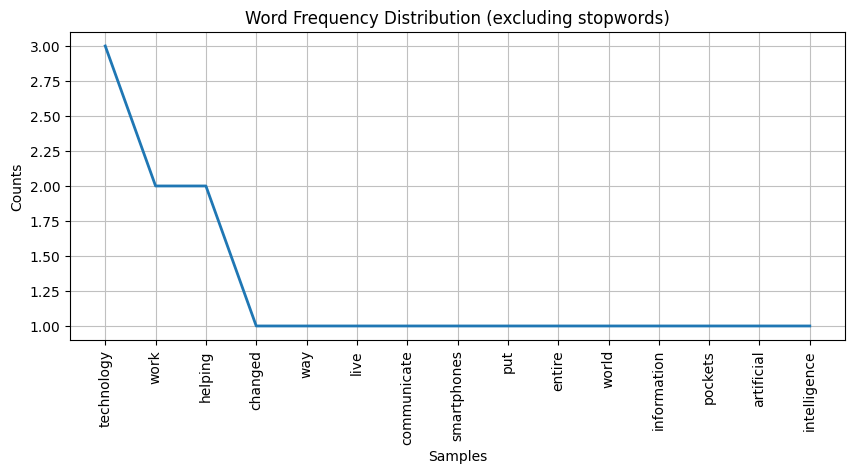

In [2]:
#Q1. Preprocessing
import re
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Your own paragraph (5-6 sentences)
paragraph = """Technology has changed the way we live, work and communicate. Smartphones put the entire world of information in our pockets. Artificial intelligence is now helping doctors detect diseases earlier and helping students learn faster. However, technology also raises concerns about privacy and jobs. I love exploring new gadgets and learning how they work. In my opinion, technology will keep shaping a better future if we use it responsibly."""

# 1. Lowercase + remove punctuation using re
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print("Clean text:\n", clean_text)

# 2. Tokenize into words and sentences
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)
print("\nSentences:", sentences)
print("\nWords:", words)

# 3. split() vs word_tokenize()
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("\nsplit() count        :", len(split_tokens))
print("word_tokenize() count:", len(nltk_tokens))
print("split()         :", split_tokens[:12])
print("word_tokenize() :", nltk_tokens[:12])
# split() only breaks on whitespace, so punctuation sticks to words ('communicate.').
# word_tokenize() treats punctuation as separate tokens and handles contractions.

# 4. Remove stopwords
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]
print("\nWithout stopwords:", filtered_words)

# 5. Word frequency distribution
fdist = FreqDist(filtered_words)
print("\nTop 10:", fdist.most_common(10))
plt.figure(figsize=(10, 4))
fdist.plot(15, title="Word Frequency Distribution (excluding stopwords)")
plt.show()

In [3]:
#Q2. Stemming and Lemmatization (uses paragraph and stop_words from Q1)
import re
import pandas as pd
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Extract only alphabetic words with re.findall()
alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
print("Alphabetic words:", alpha_words)

# 2. Remove stopwords
alpha_filtered = [w for w in alpha_words if w not in stop_words]
print("\nAfter stopword removal:", alpha_filtered)

# 3. Stemming
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in alpha_filtered]
print("\nStemmed:", stemmed)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in alpha_filtered]
print("\nLemmatized:", lemmatized)

# 5. Compare
df = pd.DataFrame({"Original": alpha_filtered, "Stemmed": stemmed, "Lemmatized": lemmatized})
print("\n", df.to_string(index=False))

print("""
Explanation:
- Stemming chops suffixes with fixed rules. It is fast but can produce non-words
  (e.g. 'technology' -> 'technolog', 'responsibly' -> 'respons').
- Lemmatization uses a dictionary (WordNet) and returns real words
  (e.g. 'diseases' -> 'disease', 'doctors' -> 'doctor').
- Prefer stemming for speed on large data / search engines.
- Prefer lemmatization when meaning and readable output matter (sentiment analysis, chatbots).
""")

Alphabetic words: ['technology', 'has', 'changed', 'the', 'way', 'we', 'live', 'work', 'and', 'communicate', 'smartphones', 'put', 'the', 'entire', 'world', 'of', 'information', 'in', 'our', 'pockets', 'artificial', 'intelligence', 'is', 'now', 'helping', 'doctors', 'detect', 'diseases', 'earlier', 'and', 'helping', 'students', 'learn', 'faster', 'however', 'technology', 'also', 'raises', 'concerns', 'about', 'privacy', 'and', 'jobs', 'i', 'love', 'exploring', 'new', 'gadgets', 'and', 'learning', 'how', 'they', 'work', 'in', 'my', 'opinion', 'technology', 'will', 'keep', 'shaping', 'a', 'better', 'future', 'if', 'we', 'use', 'it', 'responsibly']

After stopword removal: ['technology', 'changed', 'way', 'live', 'work', 'communicate', 'smartphones', 'put', 'entire', 'world', 'information', 'pockets', 'artificial', 'intelligence', 'helping', 'doctors', 'detect', 'diseases', 'earlier', 'helping', 'students', 'learn', 'faster', 'however', 'technology', 'also', 'raises', 'concerns', 'privacy

In [4]:
#Q3. Bag of Words and TF-IDF
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Your own 3 short texts (e.g. headlines)
texts = [
    "Government announces new policy to boost electric vehicle sales",
    "Local team wins the national cricket championship after thrilling final",
    "Tech company launches new smartphone with advanced camera and faster processor",
]

# 1. Bag of Words (stopwords removed)
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
print("Bag of Words:\n", pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

# 2. TF-IDF scores (stopwords removed)
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(texts)
features = tfidf.get_feature_names_out()
print("\nTF-IDF:\n", pd.DataFrame(tfidf_matrix.toarray(), columns=features).round(3))

# 3. Top 3 keywords per text
print()
for i, row in enumerate(tfidf_matrix.toarray()):
    top3 = np.argsort(row)[::-1][:3]
    print(f"Text {i+1}: {texts[i]}")
    for idx in top3:
        print(f"   {features[idx]:<15} {row[idx]:.3f}")

# Interpretation: a high TF-IDF score means the word is frequent in that text but rare in
# the other texts, so it is a distinctive keyword for that text. Words that appear in
# several texts (like 'new') get lower scores.

Bag of Words:
    advanced  announces  boost  camera  championship  company  cricket  \
0         0          1      1       0             0        0        0   
1         0          0      0       0             1        0        1   
2         1          0      0       1             0        1        0   

   electric  faster  final  ...  new  policy  processor  sales  smartphone  \
0         1       0      0  ...    1       1          0      1           0   
1         0       0      1  ...    0       0          0      0           0   
2         0       1      0  ...    1       0          1      0           1   

   team  tech  thrilling  vehicle  wins  
0     0     0          0        1     0  
1     1     0          1        0     1  
2     0     1          0        0     0  

[3 rows x 24 columns]

TF-IDF:
    advanced  announces  boost  camera  championship  company  cricket  \
0     0.000      0.363  0.363   0.000         0.000    0.000    0.000   
1     0.000      0.000  0.000   

In [5]:
#Q4. Text similarity
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_a = ("Artificial Intelligence enables machines to learn from data and make decisions. "
          "It powers applications like speech recognition, image analysis and recommendation systems. "
          "Machine learning models improve their accuracy as they see more data.")
text_b = ("Blockchain is a distributed ledger that records transactions securely across many computers. "
          "Each block is linked to the previous one using cryptography. "
          "It is widely used in cryptocurrencies and secure data sharing.")

# 1. Preprocess and tokenize
stop_words = set(stopwords.words("english"))
def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text.lower())
    return [t for t in word_tokenize(text) if t not in stop_words]

tokens_a, tokens_b = preprocess(text_a), preprocess(text_b)
print("Text A tokens:", tokens_a)
print("Text B tokens:", tokens_b)

# 2a. Jaccard similarity using sets
set_a, set_b = set(tokens_a), set(tokens_b)
jaccard = len(set_a & set_b) / len(set_a | set_b)
print("\nCommon words:", set_a & set_b)
print("Jaccard similarity:", round(jaccard, 4))

# 2b. Cosine similarity using TfidfVectorizer + cosine_similarity()
docs = [" ".join(tokens_a), " ".join(tokens_b)]
vecs = TfidfVectorizer().fit_transform(docs)
cos_sim = cosine_similarity(vecs[0], vecs[1])[0][0]
print("Cosine similarity:", round(cos_sim, 4))

# 2c. Analysis
print(f"""
Jaccard = {jaccard:.4f}, Cosine = {cos_sim:.4f}
Jaccard only checks which words are shared and ignores frequency and importance.
Cosine similarity on TF-IDF weights words by importance, so it gives better insight,
especially for documents of different lengths. Both scores are low here because
the topics (AI vs Blockchain) are different.
""")

Text A tokens: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'make', 'decisions', 'powers', 'applications', 'like', 'speech', 'recognition', 'image', 'analysis', 'recommendation', 'systems', 'machine', 'learning', 'models', 'improve', 'accuracy', 'see', 'data']
Text B tokens: ['blockchain', 'distributed', 'ledger', 'records', 'transactions', 'securely', 'across', 'many', 'computers', 'block', 'linked', 'previous', 'one', 'using', 'cryptography', 'widely', 'used', 'cryptocurrencies', 'secure', 'data', 'sharing']

Common words: {'data'}
Jaccard similarity: 0.0233
Cosine similarity: 0.0456

Jaccard = 0.0233, Cosine = 0.0456
Jaccard only checks which words are shared and ignores frequency and importance.
Cosine similarity on TF-IDF weights words by importance, so it gives better insight,
especially for documents of different lengths. Both scores are low here because
the topics (AI vs Blockchain) are different.



                                          Review  Polarity  Subjectivity   VADER
This phone is amazing! The camera quality is ...     0.875         0.950  0.8313
Terrible experience. The screen cracked in a ...    -0.750         0.600 -0.7096
The phone is okay. It works as described, not...     0.429         0.536 -0.0920
Absolutely love the design and the fast perfo...     0.358         0.433  0.7893
Very disappointed. The battery drains quickly...    -0.321         0.738 -0.5256
Great display and smooth software. Highly rec...     0.453         0.597  0.7346

                                                                                Review Sentiment
This phone is amazing! The camera quality is excellent and the battery lasts all day.  Positive
  Terrible experience. The screen cracked in a week and customer service was useless.  Negative
                           The phone is okay. It works as described, nothing special.  Negative
        Absolutely love the design and the fast

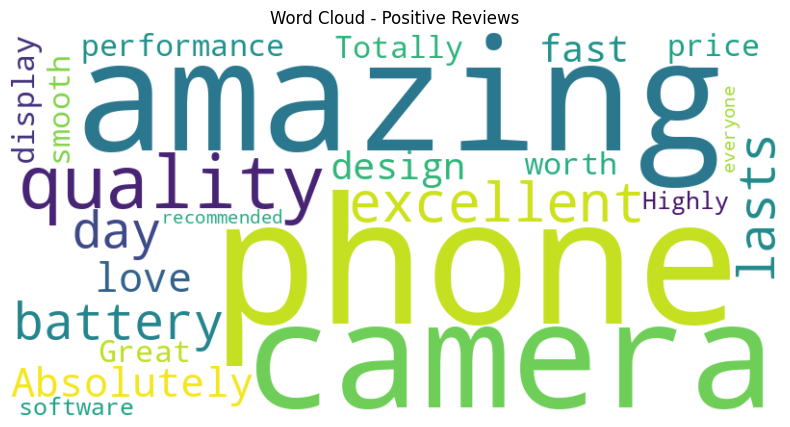

In [6]:
#Q5. Sentiment analysis
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

# Your own reviews of a product (smartphone)
reviews = [
    "This phone is amazing! The camera quality is excellent and the battery lasts all day.",
    "Terrible experience. The screen cracked in a week and customer service was useless.",
    "The phone is okay. It works as described, nothing special.",
    "Absolutely love the design and the fast performance. Totally worth the price!",
    "Very disappointed. The battery drains quickly and the phone keeps hanging.",
    "Great display and smooth software. Highly recommended for everyone.",
]

# 1. Polarity & subjectivity (TextBlob) + VADER compound score
vader = SentimentIntensityAnalyzer()
rows = []
for r in reviews:
    blob = TextBlob(r)
    rows.append({
        "Review": r[:45] + "...",
        "Polarity": round(blob.sentiment.polarity, 3),
        "Subjectivity": round(blob.sentiment.subjectivity, 3),
        "VADER": vader.polarity_scores(r)["compound"],
    })
print(pd.DataFrame(rows).to_string(index=False))

# 2. Classify as Positive / Negative / Neutral
def classify(text):
    score = vader.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

results = pd.DataFrame({"Review": reviews, "Sentiment": [classify(r) for r in reviews]})
print("\n", results.to_string(index=False))

# 3. Word cloud for all positive reviews
positive_text = " ".join(results[results["Sentiment"] == "Positive"]["Review"])
wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=STOPWORDS).generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()

In [7]:
#Q6. Text generation with LSTM
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Your own paragraph (~100 words) as training data
training_text = """Machine learning is a branch of artificial intelligence that allows computers to learn from data.
Instead of writing fixed rules, we give the computer many examples and it finds patterns on its own.
Deep learning uses neural networks with many layers to understand images, speech and language.
These models need a lot of data and computing power to train well.
Once trained, they can recognize faces, translate languages and even generate new text.
Learning how these models work is an exciting journey for every student of computer science.
With practice and curiosity anyone can build intelligent systems that solve real problems."""

# 1. Tokenize with Keras Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)

# 2. Create input sequences and build the LSTM model
input_sequences = []
for line in training_text.split("\n"):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[: i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X = input_sequences[:, :-1]
y = to_categorical(input_sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 64),
    LSTM(128),
    Dense(total_words, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()

# 3. Train (more epochs for a better fit), then generate new lines from seed words
history = model.fit(X, y, epochs=600, verbose=0)
print("Final accuracy:", round(history.history["accuracy"][-1], 3))

def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding="pre")
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                seed_text += " " + word
                break
    return seed_text

for seed in ["machine", "deep learning", "these models"]:
    print(generate_text(seed, next_words=10))

Vocabulary size: 81


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 17, 64)         │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 81)             │        10,449 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,449 (447.07 KB)

 Trainable params: 114,449 (447.07 KB)

 Non-trainable params: 0 (0.00 B)

Final accuracy: 1.0
machine learning is a branch of artificial intelligence that allows computers
deep learning uses neural networks with many layers to understand images speech
these models need a lot of data and computing power to train
